In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 120)
pd.set_option("display.max_rows", 100)
pd.set_option("display.width", 160)
pd.set_option("display.max_colwidth", 80)

print("Pandas version:", pd.__version__)

Pandas version: 3.0.5


In [2]:
# Change this path to the actual CSV location on your computer.
DATA_PATH = Path("data/raw/diabetic_data.csv")

candidate_paths = [
    DATA_PATH,
    Path("diabetic_data.csv"),
    Path("data/diabetic_data.csv"),
    Path("data/raw/diabetic_data.csv"),
]

csv_path = next((p for p in candidate_paths if p.exists()), None)

if csv_path is None:
    raise FileNotFoundError(
        "Could not find diabetic_data.csv. Set DATA_PATH to the full path, "
        "for example: Path(r'D:\\HealthcareProject\\data\\raw\\diabetic_data.csv')"
    )

df = pd.read_csv(csv_path, na_values=["?"], low_memory=False)
print("Loaded:", csv_path.resolve())
print("Rows:", f"{len(df):,}")
print("Columns:", len(df.columns))
display(df.head())

Loaded: D:\Hospital Management System\data\raw\diabetic_data.csv
Rows: 101,766
Columns: 50


,encounter_id,patient_nbr,race,gender,age,weight,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,payer_code,medical_specialty,num_lab_procedures,num_procedures,num_medications,number_outpatient,number_emergency,number_inpatient,diag_1,diag_2,diag_3,number_diagnoses,max_glu_serum,A1Cresult,metformin,repaglinide,nateglinide,chlorpropamide,glimepiride,acetohexamide,glipizide,glyburide,tolbutamide,pioglitazone,rosiglitazone,acarbose,miglitol,troglitazone,tolazamide,examide,citoglipton,insulin,glyburide-metformin,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed,readmitted
0,2278392,8222157,Caucasian,Female,[0-10),NaN,6,25,1,1,NaN,Pediatrics-Endocrinology,41,0,1,0,0,0,250.83,NaN,NaN,1,NaN,NaN,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,NO
1,149190,55629189,Caucasian,Female,[10-20),NaN,1,1,7,3,NaN,NaN,59,0,18,0,0,0,276,250.01,255,9,NaN,NaN,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Up,No,No,No,No,No,Ch,Yes,>30
2,64410,86047875,AfricanAmerican,Female,[20-30),NaN,1,1,7,2,NaN,NaN,11,5,13,2,0,1,648,250,V27,6,NaN,NaN,No,No,No,No,No,No,Steady,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Yes,NO
3,500364,82442376,Caucasian,Male,[30-40),NaN,1,1,7,2,NaN,NaN,44,1,16,0,0,0,8,250.43,403,7,NaN,NaN,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Up,No,No,No,No,No,Ch,Yes,NO
4,16680,42519267,Caucasian,Male,[40-50),NaN,1,1,7,1,NaN,NaN,51,0,8,0,0,0,197,157,250,5,NaN,NaN,No,No,No,No,No,No,Steady,No,No,No,No,No,No,No,No,No,No,Steady,No,No,No,No,No,Ch,Yes,NO


In [4]:
print("Shape:", df.shape)
print("\\nColumn names:")
for i, col in enumerate(df.columns, start=1):
    print(f"{i:02d}. {col}")

Shape: (101766, 50)
\nColumn names:
01. encounter_id
02. patient_nbr
03. race
04. gender
05. age
06. weight
07. admission_type_id
08. discharge_disposition_id
09. admission_source_id
10. time_in_hospital
11. payer_code
12. medical_specialty
13. num_lab_procedures
14. num_procedures
15. num_medications
16. number_outpatient
17. number_emergency
18. number_inpatient
19. diag_1
20. diag_2
21. diag_3
22. number_diagnoses
23. max_glu_serum
24. A1Cresult
25. metformin
26. repaglinide
27. nateglinide
28. chlorpropamide
29. glimepiride
30. acetohexamide
31. glipizide
32. glyburide
33. tolbutamide
34. pioglitazone
35. rosiglitazone
36. acarbose
37. miglitol
38. troglitazone
39. tolazamide
40. examide
41. citoglipton
42. insulin
43. glyburide-metformin
44. glipizide-metformin
45. glimepiride-pioglitazone
46. metformin-rosiglitazone
47. metformin-pioglitazone
48. change
49. diabetesMed
50. readmitted


## 4. Data types and initial structure

`info()` shows data types and non-null counts. Many coded fields may be stored as text in the raw CSV, so do not assume their type from the column name alone.

In [5]:
df.info()
display(pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "non_null_count": df.notna().sum(),
    "missing_count": df.isna().sum(),
    "missing_percent": (df.isna().mean() * 100).round(2),
}).sort_values("missing_percent", ascending=False))

<class 'pandas.DataFrame'>
RangeIndex: 101766 entries, 0 to 101765
Data columns (total 50 columns):
 #   Column                    Non-Null Count   Dtype
---  ------                    --------------   -----
 0   encounter_id              101766 non-null  int64
 1   patient_nbr               101766 non-null  int64
 2   race                      99493 non-null   str  
 3   gender                    101766 non-null  str  
 4   age                       101766 non-null  str  
 5   weight                    3197 non-null    str  
 6   admission_type_id         101766 non-null  int64
 7   discharge_disposition_id  101766 non-null  int64
 8   admission_source_id       101766 non-null  int64
 9   time_in_hospital          101766 non-null  int64
 10  payer_code                61510 non-null   str  
 11  medical_specialty         51817 non-null   str  
 12  num_lab_procedures        101766 non-null  int64
 13  num_procedures            101766 non-null  int64
 14  num_medications           10176

,dtype,non_null_count,missing_count,missing_percent
weight,str,3197,98569,96.86
max_glu_serum,str,5346,96420,94.75
A1Cresult,str,17018,84748,83.28
medical_specialty,str,51817,49949,49.08
payer_code,str,61510,40256,39.56
race,str,99493,2273,2.23
diag_3,str,100343,1423,1.40
diag_2,str,101408,358,0.35
diag_1,str,101745,21,0.02
patient_nbr,int64,101766,0,0.00


## 5. Missing-value profile

The source commonly represents missing values using `?`; the loading step converts those to Pandas missing values. Review both the count and percentage before choosing a cleaning rule.

,missing_count,missing_percent
weight,98569,96.86
max_glu_serum,96420,94.75
A1Cresult,84748,83.28
medical_specialty,49949,49.08
payer_code,40256,39.56
race,2273,2.23
diag_3,1423,1.40
diag_2,358,0.35
diag_1,21,0.02


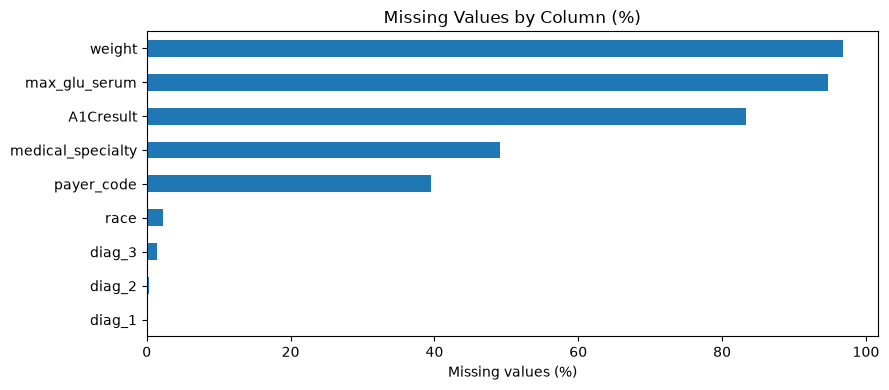

In [6]:
missing_summary = pd.DataFrame({
    "missing_count": df.isna().sum(),
    "missing_percent": (df.isna().mean() * 100).round(2),
})
missing_summary = missing_summary[missing_summary["missing_count"] > 0].sort_values(
    "missing_percent", ascending=False
)
display(missing_summary)

if not missing_summary.empty:
    missing_summary["missing_percent"].sort_values().plot(
        kind="barh", figsize=(9, max(4, len(missing_summary) * 0.25))
    )
    plt.title("Missing Values by Column (%)")
    plt.xlabel("Missing values (%)")
    plt.tight_layout()
    plt.show()
else:
    print("No missing values detected after converting '?' to NaN.")

## 6. Duplicate checks and identifier checks

Check exact duplicate rows and duplicate identifiers separately. Repeated `patient_nbr` values are expected because one patient can have multiple encounters. Repeated `encounter_id` values generally require investigation.

In [7]:
exact_duplicate_rows = int(df.duplicated().sum())
print("Exact duplicate rows:", f"{exact_duplicate_rows:,}")

for col in ["encounter_id", "patient_nbr"]:
    if col in df.columns:
        print(f"\\n{col}")
        print("Missing:", int(df[col].isna().sum()))
        print("Unique non-missing:", int(df[col].nunique(dropna=True)))
        print("Repeated rows beyond first occurrence:", int(df[col].duplicated(keep="first").sum()))

if "encounter_id" in df.columns:
    duplicate_encounters = df[df["encounter_id"].duplicated(keep=False)].sort_values("encounter_id")
    print("\\nRows belonging to duplicated encounter IDs:", len(duplicate_encounters))
    display(duplicate_encounters.head(20))

Exact duplicate rows: 0
\nencounter_id
Missing: 0
Unique non-missing: 101766
Repeated rows beyond first occurrence: 0
\npatient_nbr
Missing: 0
Unique non-missing: 71518
Repeated rows beyond first occurrence: 30248
\nRows belonging to duplicated encounter IDs: 0


,encounter_id,patient_nbr,race,gender,age,weight,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,payer_code,medical_specialty,num_lab_procedures,num_procedures,num_medications,number_outpatient,number_emergency,number_inpatient,diag_1,diag_2,diag_3,number_diagnoses,max_glu_serum,A1Cresult,metformin,repaglinide,nateglinide,chlorpropamide,glimepiride,acetohexamide,glipizide,glyburide,tolbutamide,pioglitazone,rosiglitazone,acarbose,miglitol,troglitazone,tolazamide,examide,citoglipton,insulin,glyburide-metformin,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed,readmitted


## 7. Categorical-column profiling

Inspect the most common values and their frequencies. This helps identify inconsistent labels, unexpected codes, and fields that should be normalized. High-cardinality columns are limited to their 15 most frequent values.

In [8]:
categorical_candidates = df.select_dtypes(include=["object", "category"]).columns.tolist()
print("Text/category columns:", len(categorical_candidates))

for col in categorical_candidates:
    print(f"\\n--- {col} ---")
    print("Unique values:", df[col].nunique(dropna=True))
    display(df[col].value_counts(dropna=False).head(15).rename_axis("value").to_frame("count"))

Text/category columns: 37
\n--- race ---
Unique values: 5


C:\Users\sachein.diwakar\AppData\Local\Temp\ipykernel_31704\4214151053.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_candidates = df.select_dtypes(include=["object", "category"]).columns.tolist()


,count
value,
Caucasian,76099
AfricanAmerican,19210
NaN,2273
Hispanic,2037
Other,1506
Asian,641


\n--- gender ---
Unique values: 3


,count
value,
Female,54708
Male,47055
Unknown/Invalid,3


...

,count
value,
No,54755
Ch,47011


\n--- diabetesMed ---
Unique values: 2


,count
value,
Yes,78363
No,23403


\n--- readmitted ---
Unique values: 3


,count
value,
NO,54864
>30,35545
<30,11357


## 8. Numeric-column profiling

Review ranges and summary statistics. Some fields may be numeric in meaning but represented as text; this section profiles columns Pandas currently recognizes as numeric.

In [9]:
numeric_cols = df.select_dtypes(include=[np.number]).columns.tolist()
print("Numeric columns:", numeric_cols)
display(df[numeric_cols].describe().T if numeric_cols else pd.DataFrame())

# Attempt a non-destructive numeric conversion for selected fields to reveal parsing issues.
numeric_candidates = [
    "time_in_hospital", "num_lab_procedures", "num_procedures",
    "num_medications", "number_outpatient", "number_emergency",
    "number_inpatient", "number_diagnoses"
]
for col in numeric_candidates:
    if col in df.columns:
        converted = pd.to_numeric(df[col], errors="coerce")
        invalid = df[col].notna() & converted.isna()
        print(f"{col}: invalid non-null numeric values = {int(invalid.sum())}")

Numeric columns: ['encounter_id', 'patient_nbr', 'admission_type_id', 'discharge_disposition_id', 'admission_source_id', 'time_in_hospital', 'num_lab_procedures', 'num_procedures', 'num_medications', 'number_outpatient', 'number_emergency', 'number_inpatient', 'number_diagnoses']


,count,mean,std,min,25%,50%,75%,max
encounter_id,101766.0,1.652016e+08,1.026403e+08,12522.0,84961194.0,152388987.0,2.302709e+08,443867222.0
patient_nbr,101766.0,5.433040e+07,3.869636e+07,135.0,23413221.0,45505143.0,8.754595e+07,189502619.0
admission_type_id,101766.0,2.024006e+00,1.445403e+00,1.0,1.0,1.0,3.000000e+00,8.0
discharge_disposition_id,101766.0,3.715642e+00,5.280166e+00,1.0,1.0,1.0,4.000000e+00,28.0
admission_source_id,101766.0,5.754437e+00,4.064081e+00,1.0,1.0,7.0,7.000000e+00,25.0
time_in_hospital,101766.0,4.395987e+00,2.985108e+00,1.0,2.0,4.0,6.000000e+00,14.0
num_lab_procedures,101766.0,4.309564e+01,1.967436e+01,1.0,31.0,44.0,5.700000e+01,132.0
num_procedures,101766.0,1.339730e+00,1.705807e+00,0.0,0.0,1.0,2.000000e+00,6.0
num_medications,101766.0,1.602184e+01,8.127566e+00,1.0,10.0,15.0,2.000000e+01,81.0
number_outpatient,101766.0,3.693572e-01,1.267265e+00,0.0,0.0,0.0,0.000000e+00,42.0


time_in_hospital: invalid non-null numeric values = 0
num_lab_procedures: invalid non-null numeric values = 0
num_procedures: invalid non-null numeric values = 0
num_medications: invalid non-null numeric values = 0
number_outpatient: invalid non-null numeric values = 0
number_emergency: invalid non-null numeric values = 0
number_inpatient: invalid non-null numeric values = 0
number_diagnoses: invalid non-null numeric values = 0


## 9. Check key categorical values

These checks are descriptive, not automatic cleaning. The accepted values are based on the commonly distributed UCI dataset; investigate any unexpected values before changing them.

In [11]:
expected_values = {
    "gender": {"Male", "Female", "Unknown/Invalid"},
    "readmitted": {"<30", ">30", "NO"},
    "change": {"Ch", "No"},
    "diabetesMed": {"Yes", "No"},
    "insulin": {"Up", "Down", "Steady", "No"},
}

for col, expected in expected_values.items():
    if col in df.columns:
        observed = set(df[col].dropna().astype(str).unique())
        print(f"\\n{col}")
        print("Observed values:", sorted(observed))
        print("Unexpected values:", sorted(observed - expected))
        print("Missing values:", int(df[col].isna().sum()))

\ngender
Observed values: ['Female', 'Male', 'Unknown/Invalid']
Unexpected values: []
Missing values: 0
\nreadmitted
Observed values: ['<30', '>30', 'NO']
Unexpected values: []
Missing values: 0
\nchange
Observed values: ['Ch', 'No']
Unexpected values: []
Missing values: 0
\ndiabetesMed
Observed values: ['No', 'Yes']
Unexpected values: []
Missing values: 0
\ninsulin
Observed values: ['Down', 'No', 'Steady', 'Up']
Unexpected values: []
Missing values: 0


## 10. Readmission distribution

The target field `readmitted` contains `<30`, `>30`, and `NO`. These are encounter-level labels. The dataset does not provide a precise admission/discharge timestamp for each encounter, so the standard `time_in_hospital` field should not be treated as a calendar date.

,encounters
readmitted,
NO,54864
>30,35545
<30,11357


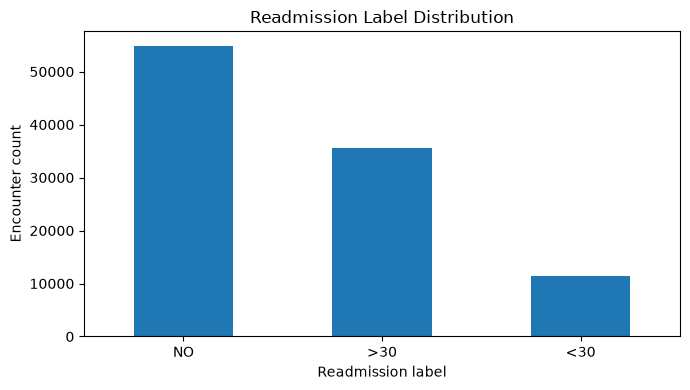

Encounters labelled readmitted within 30 days: 11,357 (11.16%)


In [12]:
if "readmitted" in df.columns:
    readmission_counts = df["readmitted"].value_counts(dropna=False)
    display(readmission_counts.rename_axis("readmitted").to_frame("encounters"))

    readmission_counts.plot(kind="bar", figsize=(7, 4))
    plt.title("Readmission Label Distribution")
    plt.xlabel("Readmission label")
    plt.ylabel("Encounter count")
    plt.xticks(rotation=0)
    plt.tight_layout()
    plt.show()

    # A commonly useful metric: readmission within 30 days among all rows.
    # This is an encounter-level proportion, not a causal or patient-level risk estimate.
    if len(df):
        within_30 = (df["readmitted"] == "<30").sum()
        print(f"Encounters labelled readmitted within 30 days: {within_30:,} ({within_30 / len(df) * 100:.2f}%)")

## 11. Length-of-stay analysis

`time_in_hospital` is the number of days in the hospital, not a date. Compare its distribution and mean across readmission categories.

count    101766.000000
mean          4.395987
std           2.985108
min           1.000000
25%           2.000000
50%           4.000000
75%           6.000000
max          14.000000
Name: time_in_hospital, dtype: float64


,encounter_count,mean_days,median_days,min_days,max_days
readmitted,,,,,
<30,11357,4.77,4.0,1,14
>30,35545,4.50,4.0,1,14
NO,54864,4.25,3.0,1,14


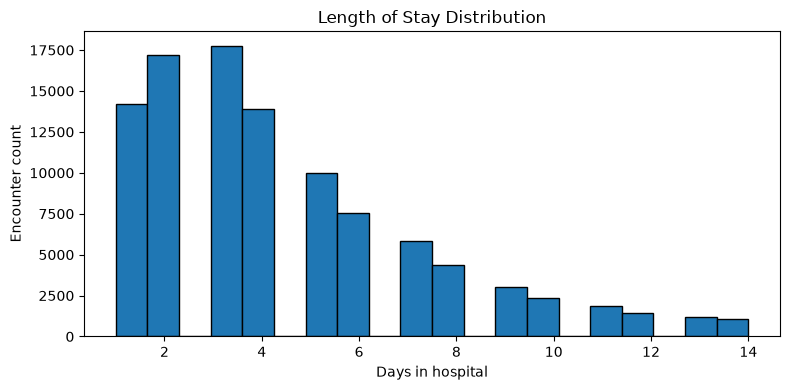

In [13]:
if "time_in_hospital" in df.columns:
    los = pd.to_numeric(df["time_in_hospital"], errors="coerce")
    print(los.describe())
    display(df.assign(_los=los).groupby("readmitted", dropna=False)["_los"].agg(
        encounter_count="count", mean_days="mean", median_days="median",
        min_days="min", max_days="max"
    ).round(2) if "readmitted" in df.columns else los.describe().to_frame())

    los.dropna().plot(kind="hist", bins=20, figsize=(8, 4), edgecolor="black")
    plt.title("Length of Stay Distribution")
    plt.xlabel("Days in hospital")
    plt.ylabel("Encounter count")
    plt.tight_layout()
    plt.show()

## 12. Compare readmission across admission types

The `admission_type_id` values are codes, not descriptive labels in the raw data. First inspect the data distribution by code. Use a verified code mapping only after checking the dataset documentation.

In [14]:
if {"admission_type_id", "readmitted"}.issubset(df.columns):
    admission_readmission = pd.crosstab(
        df["admission_type_id"], df["readmitted"], dropna=False
    )
    display(admission_readmission)

    admission_rates = df.assign(
        readmitted_within_30=(df["readmitted"] == "<30").astype(int)
    ).groupby("admission_type_id", dropna=False).agg(
        encounters=("encounter_id", "size") if "encounter_id" in df.columns else ("readmitted_within_30", "size"),
        readmitted_within_30=("readmitted_within_30", "sum"),
        within_30_rate=("readmitted_within_30", "mean"),
        mean_los=("time_in_hospital", "mean") if "time_in_hospital" in df.columns else ("readmitted_within_30", "mean"),
    )
    admission_rates["within_30_rate_percent"] = (admission_rates["within_30_rate"] * 100).round(2)
    display(admission_rates.sort_values("within_30_rate", ascending=False).round(2))

readmitted,<30,>30,NO
admission_type_id,,,
1,6221,19309,28460
2,2066,6452,9962
3,1961,5746,11162
4,1,2,7
5,495,1721,2569
6,586,2231,2474
7,0,0,21
8,27,84,209


,encounters,readmitted_within_30,within_30_rate,mean_los,within_30_rate_percent
admission_type_id,,,,,
1,53990,6221,0.12,4.38,11.52
2,18480,2066,0.11,4.61,11.18
6,5291,586,0.11,4.58,11.08
3,18869,1961,0.10,4.32,10.39
5,4785,495,0.10,3.95,10.34
4,10,1,0.10,3.20,10.00
8,320,27,0.08,3.06,8.44
7,21,0,0.00,4.86,0.00


## 13. Patient encounter frequency

Patients may appear in multiple rows. This summary counts encounters per `patient_nbr`; it does not mean all repeated encounters are readmissions.

,encounters_per_patient
count,71518.000000
mean,1.422942
std,1.090740
min,1.000000
25%,1.000000
50%,1.000000
75%,1.000000
max,40.000000


Unique patients (non-missing patient_nbr): 71,518
Patients with more than one encounter: 16,773


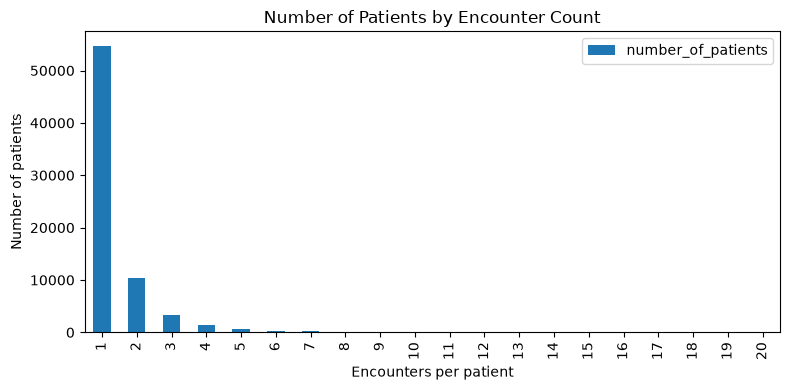

In [15]:
if "patient_nbr" in df.columns:
    encounters_per_patient = df.groupby("patient_nbr", dropna=False).size()
    display(encounters_per_patient.describe().to_frame("encounters_per_patient"))
    print("Unique patients (non-missing patient_nbr):", f"{df['patient_nbr'].nunique(dropna=True):,}")
    print("Patients with more than one encounter:", f"{int((encounters_per_patient > 1).sum()):,}")

    encounters_per_patient.value_counts().sort_index().head(20).rename_axis(
        "encounter_count"
    ).to_frame("number_of_patients").plot(kind="bar", figsize=(8, 4))
    plt.title("Number of Patients by Encounter Count")
    plt.xlabel("Encounters per patient")
    plt.ylabel("Number of patients")
    plt.tight_layout()
    plt.show()

## 14. Data-quality findings summary

This cell produces a compact report that can be saved and used to document ETL decisions. It flags issues for investigation rather than silently modifying data.

In [16]:
quality_summary = {
    "row_count": len(df),
    "column_count": len(df.columns),
    "exact_duplicate_rows": int(df.duplicated().sum()),
    "missing_cells": int(df.isna().sum().sum()),
    "columns_with_missing_values": int((df.isna().sum() > 0).sum()),
}
if "encounter_id" in df.columns:
    quality_summary["missing_encounter_ids"] = int(df["encounter_id"].isna().sum())
    quality_summary["duplicate_encounter_id_rows"] = int(df["encounter_id"].duplicated(keep=False).sum())
if "patient_nbr" in df.columns:
    quality_summary["unique_patients"] = int(df["patient_nbr"].nunique(dropna=True))
if "readmitted" in df.columns:
    quality_summary["missing_readmission_labels"] = int(df["readmitted"].isna().sum())

display(pd.Series(quality_summary, name="value").to_frame())

# Save the profile outputs beside the notebook (or change this output directory).
OUTPUT_DIR = Path("reports")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
missing_summary.to_csv(OUTPUT_DIR / "missing_values_profile.csv")
pd.Series(quality_summary, name="value").to_csv(OUTPUT_DIR / "dataset_quality_summary.csv", header=True)
print("Saved reports to:", OUTPUT_DIR.resolve())

,value
row_count,101766
column_count,50
exact_duplicate_rows,0
missing_cells,374017
columns_with_missing_values,9
missing_encounter_ids,0
duplicate_encounter_id_rows,0
unique_patients,71518
missing_readmission_labels,0


Saved reports to: D:\Hospital Management System\reports


## 15. Initial conclusions and next steps

Use the actual outputs from this notebook to finalize the cleaning rules.

1. Confirm the encounter count and column list.
2. Review missingness before deciding whether to exclude or retain a column.
3. Investigate exact duplicate rows and duplicate `encounter_id` values.
4. Treat repeated `patient_nbr` values as expected until evidence shows otherwise.
5. Keep `readmitted` as a clearly documented encounter-level outcome.
6. Do not invent admission or discharge dates; the common dataset does not include actual calendar timestamps for each encounter.
7. Map coded admission/discharge values using the dataset documentation.
8. Next, create a cleaning and validation notebook/script, then design the normalized database schema.

**Important:** This dataset is for educational analysis. Do not expose patient identifiers or unnecessary demographic attributes in public views, and do not present descriptive associations as medical advice.